# Exploratory Data Analysis (EDA)

## 1. Import Library dan Dataset

Pada tahap ini, dilakukan import library yang diperlukan untuk analisis data serta pembacaan dataset menggunakan Pandas.

Dataset yang digunakan terdiri dari tiga file:
- **train.csv**: Data yang digunakan untuk melatih dan mengevaluasi model.
- **test.csv**: Data yang digunakan untuk menghasilkan prediksi.
- **sample_submission.csv**: Contoh format pengumpulan hasil prediksi ke Kaggle.

In [11]:
# Melakukan import modul
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [12]:
# Load dataset
train = pd.read_csv(Path("..") / ".." / "data" / "train.csv")
test = pd.read_csv(Path("..") / ".." / "data" / "test.csv")
sample_submission = pd.read_csv(Path("..") / ".." / "data" / "sample_submission.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Dataset Overview

Bagian ini bertujuan memahami dimensi dataset, struktur kolom, tipe data, dan statistik deskriptif.

### Melihat dimensi dataset

In [13]:
print("Training dataset:", train.shape)
print("Testing dataset :", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

Training dataset: (27373, 19)
Testing dataset : (6844, 18)

Training columns:
['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'is_canceled']

Testing columns:
['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']


### Melihat preview dataset

In [14]:
display(train.head())
display(test.head())

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,5cb6f473,2.0,0.0,0,1,Breakfast,0.0,Type B,217.0,2024,8,11,Offline Agent,0,0,0,1299000.0,0.0
1,c06b4ab3,2.0,0.0,1,2,Breakfast,0.0,Type B,190.0,2024,6,19,Online Travel Agent,0,0,0,2010000.0,0.0
2,22bf3fc3,2.0,0.0,1,2,Breakfast,0.0,Type B,124.0,2024,5,12,Online Travel Agent,0,0,0,1921000.0,1.0
3,25408a48,NaN,0.0,2,4,Half Board,0.0,Type B,0.0,2024,1,2,Online Travel Agent,0,0,0,1451000.0,0.0
4,621586b6,2.0,1.0,2,3,Breakfast,0.0,Type G,44.0,2023,11,1,Offline Agent,0,0,0,1225000.0,2.0


### Melihat tipe data

In [15]:
train.info()

print("\nData type summary:")
display(train.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14  prior_cancellatio

int64      9
float64    6
str        4
Name: count, dtype: int64

### Descriptive statistics

In [17]:
# Numerical features
display(train.describe())

# Categorical features
display(train.describe(include=["object", "str", "category"]))

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


,id,meal_package,room_category,booking_channel
count,27373,25613,26371,27373
unique,27373,4,7,5
top,57152f82,Breakfast,Type B,Online Travel Agent
freq,1,19654,20447,17511


## 3. Analisis Kualitas Data

Bagian ini penting untuk mengetahui apakah ada data yang hilang, data yang terduplikat, atau data yang rusak

### Missing Values

In [19]:
missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100,
})

# Hanya kolom yang memiliki missing values
missing = missing.loc[missing["Missing Count"] > 0]

# Urutkan berdasarkan persentase missing values
missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False,
)

display(missing)


,Missing Count,Missing Percentage
num_children,3035,11.087568
special_requests,2500,9.133087
nightly_rate_idr,2038,7.445293
meal_package,1760,6.429693
days_before_arrival,1123,4.102583
needs_parking,1082,3.952800
room_category,1002,3.660541
num_adults,809,2.955467


### Visualisasi Missing Values

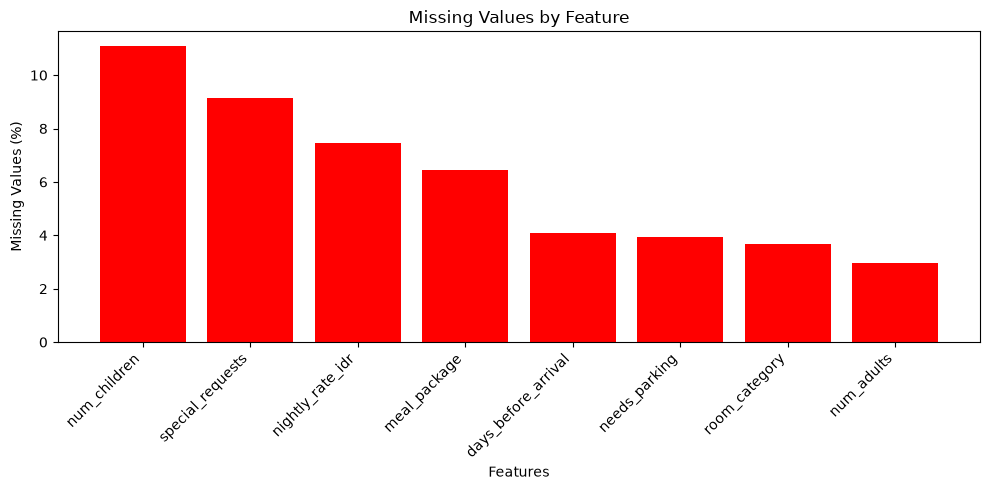

In [20]:
COLOR = "#FF0000"

plt.figure(figsize=(10, 5))

plt.bar(
    missing.index,
    missing["Missing Percentage"],
    color=COLOR,
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Duplikasi data

In [21]:
print("Train duplicates:", train.duplicated().sum())
print("Test duplicates :", test.duplicated().sum())

Train duplicates: 0
Test duplicates : 0
